# 02 - Exploratory Analysis

Answers the business questions about **transaction patterns** and **financial impact**:

1. What percentage of transactions are fraudulent?
2. What is the typical amount for fraud vs legitimate transactions?
3. Is fraud concentrated in particular hours?
4. What is the total value of fraud, and which amount ranges contain the most fraud?

> Count vs rate: a band can have *many* fraud cases simply because it has many transactions. We always look at both the **count** and the **rate**.

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, save, LEGIT_COLOR, FRAUD_COLOR, MUTED_COLOR
set_style()
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
from src.preprocessing import load_clean
from src.features import add_features

df = add_features(load_clean())
fraud = df[df["Class"] == 1]
legit = df[df["Class"] == 0]

## Q1 - How much fraud is there?

In [3]:
kpis = pd.Series({
    "Total transactions": len(df),
    "Fraud transactions": len(fraud),
    "Fraud rate (%)": 100 * len(fraud) / len(df),
    "Total value (EUR)": df["Amount"].sum(),
    "Fraud value (EUR)": fraud["Amount"].sum(),
    "Fraud share of value (%)": 100 * fraud["Amount"].sum() / df["Amount"].sum(),
})
kpis.map("{:,.3f}".format)

Total transactions             283,726.000
Fraud transactions                 473.000
Fraud rate (%)                       0.167
Total value (EUR)           25,102,001.680
Fraud value (EUR)               58,591.390
Fraud share of value (%)             0.233
dtype: str

## Q2 - Typical amount: fraud vs legitimate

In [4]:
df.groupby("Class")["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).rename(index={0: "Legitimate", 1: "Fraud"})

,count,mean,std,min,25%,50%,75%,95%,max
Class,,,,,,,,,
Legitimate,"283,253.0000",88.4136,250.3790,0.0000,5.6700,22.0000,77.4600,365.0000,"25,691.1600"
Fraud,473.0000,123.8719,260.2110,0.0000,1.0000,9.8200,105.8900,655.8200,"2,125.8700"


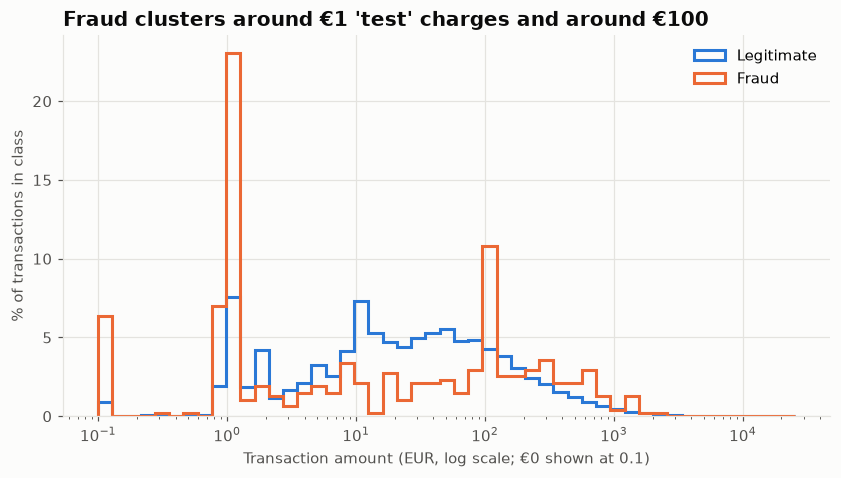

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-1, np.log10(df["Amount"].max() + 1), 50)
for data, label, color in [(legit, "Legitimate", LEGIT_COLOR), (fraud, "Fraud", FRAUD_COLOR)]:
    ax.hist(data["Amount"] + 0.1, bins=bins, weights=np.full(len(data), 100 / len(data)),
            histtype="step", linewidth=2, color=color, label=label)
ax.set_xscale("log")
ax.set_xlabel("Transaction amount (EUR, log scale; €0 shown at 0.1)")
ax.set_ylabel("% of transactions in class")
ax.set_title("Fraud clusters around €1 'test' charges and around €100")
ax.legend()
save(fig, "01_amount_distribution")
plt.show()

**Reading it:** the mean fraud amount is higher than the legitimate mean, but the *median* fraud is lower. Many frauds are tiny "test" charges (around €1) while a minority are large - so the mean is pulled up by a few big cases. That is why we report the median as the "typical" amount.

## Q4 - Fraud by amount band (count, rate and value)

In [6]:
bands = (df.groupby("amount_band", observed=True)
            .agg(transactions=("Class", "size"),
                 fraud_cases=("Class", "sum"),
                 fraud_value_eur=("Amount", lambda s: s[df.loc[s.index, "Class"] == 1].sum())))
bands["fraud_rate_pct"] = 100 * bands["fraud_cases"] / bands["transactions"]
bands["share_of_fraud_cases_pct"] = 100 * bands["fraud_cases"] / bands["fraud_cases"].sum()
bands["share_of_fraud_value_pct"] = 100 * bands["fraud_value_eur"] / bands["fraud_value_eur"].sum()
bands

,transactions,fraud_cases,fraud_value_eur,fraud_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
amount_band,,,,,,
€0-1,30331,171,131.5600,0.5638,36.1522,0.2245
€1-10,69490,67,317.7500,0.0964,14.1649,0.5423
€10-50,90327,55,"1,539.8200",0.0609,11.6279,2.6281
€50-100,37179,55,"4,867.3300",0.1479,11.6279,8.3072
€100-250,33828,54,"8,369.5900",0.1596,11.4165,14.2847
€250-500,13462,37,"12,682.6900",0.2748,7.8224,21.6460
€500-1000,6174,25,"17,445.3200",0.4049,5.2854,29.7745
€1000+,2935,9,"13,237.3300",0.3066,1.9027,22.5926


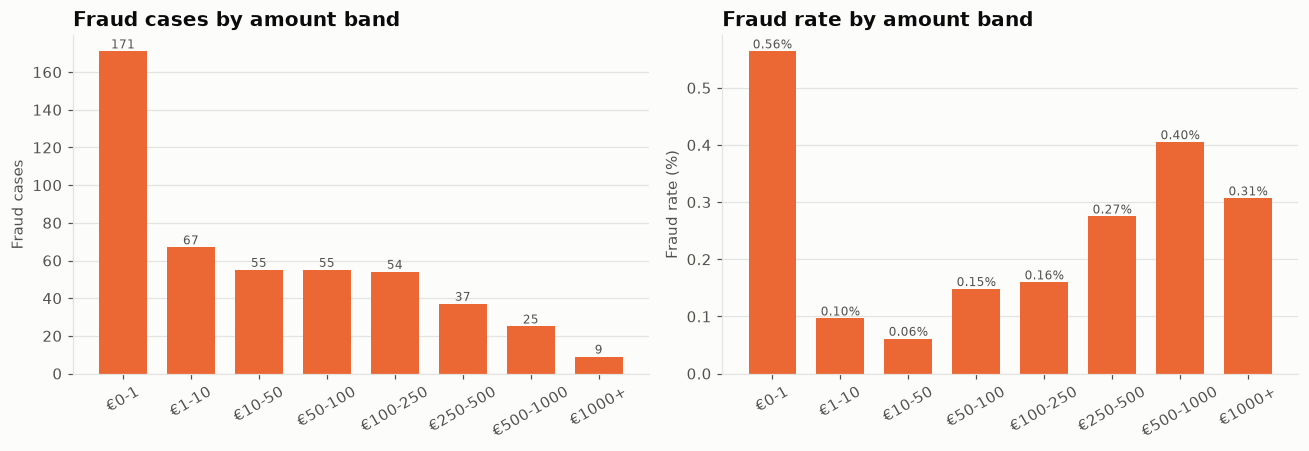

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(bands.index.astype(str), bands["fraud_cases"], color=FRAUD_COLOR, width=0.7)
axes[0].set_title("Fraud cases by amount band")
axes[0].set_ylabel("Fraud cases")
axes[1].bar(bands.index.astype(str), bands["fraud_rate_pct"], color=FRAUD_COLOR, width=0.7)
axes[1].set_title("Fraud rate by amount band")
axes[1].set_ylabel("Fraud rate (%)")
for ax, col, fmt in [(axes[0], "fraud_cases", "{:,.0f}"), (axes[1], "fraud_rate_pct", "{:.2f}%")]:
    for x, v in enumerate(bands[col]):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=8, color=MUTED_COLOR)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "02_fraud_by_amount_band")
plt.show()

**Reading it:** most fraud *cases* are tiny (€0-1), but they are worth almost nothing. Most fraud *value* sits in the €250+ bands, which have few cases but a high fraud rate. Count, rate and value tell three different stories - a monitoring team needs all three.

## Q3 - Is fraud concentrated in particular hours?

`Time` is seconds since the first transaction. We assume the data starts at midnight to get an hour of day (an assumption - the provider doesn't state it).

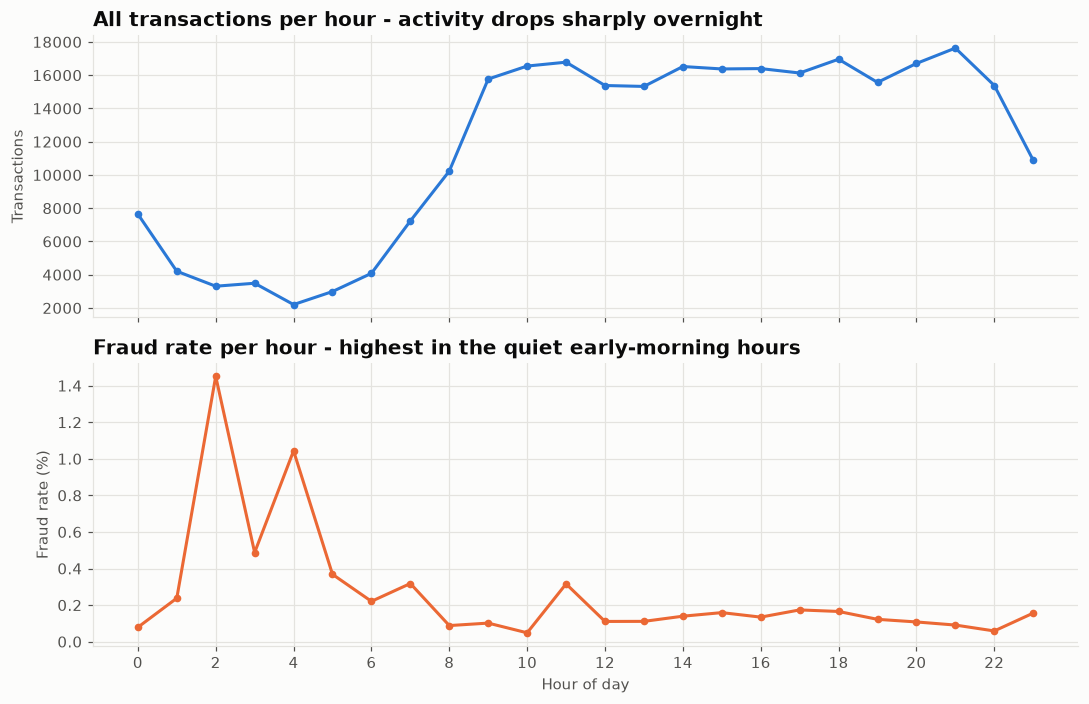

,transactions,fraud_cases,fraud_rate_pct
hour,,,
2,3308,48,1.4510
4,2204,23,1.0436
3,3487,17,0.4875
5,2988,11,0.3681
7,7233,23,0.3180


In [8]:
hourly = df.groupby("hour").agg(transactions=("Class", "size"), fraud_cases=("Class", "sum"))
hourly["fraud_rate_pct"] = 100 * hourly["fraud_cases"] / hourly["transactions"]

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
axes[0].plot(hourly.index, hourly["transactions"], color=LEGIT_COLOR, marker="o", markersize=4)
axes[0].set_title("All transactions per hour - activity drops sharply overnight")
axes[0].set_ylabel("Transactions")
axes[1].plot(hourly.index, hourly["fraud_rate_pct"], color=FRAUD_COLOR, marker="o", markersize=4)
axes[1].set_title("Fraud rate per hour - highest in the quiet early-morning hours")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_xlabel("Hour of day")
axes[1].set_xticks(range(0, 24, 2))
fig.tight_layout()
save(fig, "03_fraud_by_hour")
plt.show()

hourly.sort_values("fraud_rate_pct", ascending=False).head(5)

**Reading it:** fraud *counts* follow overall activity, but the fraud *rate* jumps in the early-morning hours when few genuine customers are shopping. Night-time transactions deserve extra scrutiny.

## Which anonymised components differ most between fraud and legitimate?

These are PCA components, so we only say *"V14 separates the classes well"* - never *"V14 means X"*.

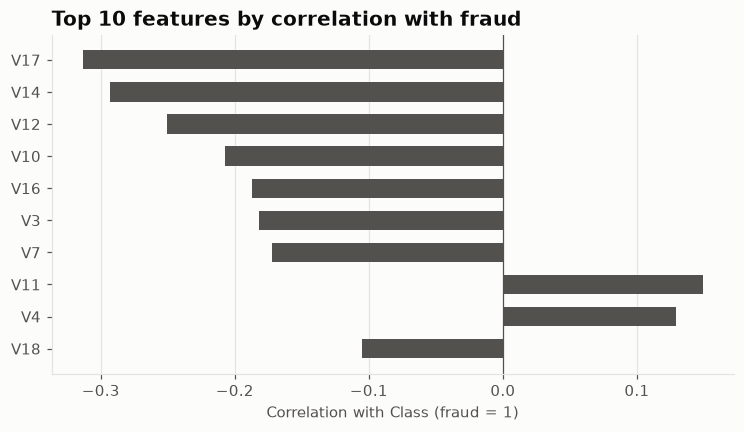

In [9]:
corr = df[[f"V{i}" for i in range(1, 29)] + ["log_amount", "hour", "Class"]].corr()["Class"].drop("Class")
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index[::-1], top.values[::-1], color=MUTED_COLOR, height=0.6)
ax.axvline(0, color=MUTED_COLOR, linewidth=0.8)
ax.set_title("Top 10 features by correlation with fraud")
ax.set_xlabel("Correlation with Class (fraud = 1)")
ax.grid(axis="y", visible=False)
save(fig, "04_feature_correlation")
plt.show()

## Export for SQL and Tableau

We drop the 28 PCA columns - they are not meaningful to a business audience.

In [10]:
from pathlib import Path
out = Path("../dashboard/data"); out.mkdir(parents=True, exist_ok=True)

export = df[["transaction_id", "Time", "day", "hour", "Amount", "amount_band", "Class"]].rename(
    columns={"Time": "time_seconds", "Amount": "amount", "Class": "is_fraud"})
export.to_csv(out / "transactions.csv", index=False)
print(f"Saved {len(export):,} rows to dashboard/data/transactions.csv")

Saved 283,726 rows to dashboard/data/transactions.csv
